<a href="https://colab.research.google.com/github/christinafan-cell/MSSP607/blob/main/Assignments/Week_12/Week_12_Christina_Fan.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 12: Statistics and Hypothesis Testing
**Christina Fan | MSSP607**

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from urllib.parse import quote
from urllib.error import HTTPError
from IPython.display import display

# Read the dataset directly from the GitHub repository.
base_url = 'https://raw.githubusercontent.com/christinafan-cell/MSSP607/main/data/'
file_names = ['Student Performance Data.csv', 'Student Performance Data (1).csv']
for file_name in file_names:
    try:
        df = pd.read_csv(base_url + quote(file_name))
        print('Loaded from GitHub:', file_name)
        break
    except HTTPError as error:
        if error.code != 404:
            raise
else:
    raise FileNotFoundError('Upload Student Performance Data.csv to the data folder of christinafan-cell/MSSP607 (main branch), then run again.')

# Standardize column names and category labels.
df.columns = df.columns.str.strip().str.lower()
for col in ['gender', 'test preparation course', 'lunch']:
    df[col] = df[col].str.strip().str.lower()
subjects = ['math score', 'reading score', 'writing score']
for col in subjects:
    df[col] = pd.to_numeric(df[col], errors='coerce')
# Require all three subject scores when calculating the total.
df['total score'] = df[subjects].sum(axis=1, min_count=3)
scores = ['total score'] + subjects
print('Rows and columns:', df.shape)
display(df.head())
display(df[scores].describe().round(2))
print('Missing values:')
print(df[['gender', 'test preparation course', 'lunch'] + scores].isna().sum())

Loaded from GitHub: Student Performance Data.csv
Rows and columns: (1000, 10)


,gender,race/ethnicity,parental level of education,lunch,math score,reading score,writing score,total score,test preparation course,admission prospect
0,female,group B,bachelor's degree,standard,72,72,74,218,none,medium
1,female,group C,some college,standard,69,90,88,247,completed,high
2,female,group B,master's degree,standard,90,95,93,278,none,high
3,male,group A,associate's degree,free/reduced,47,57,44,148,none,low
4,male,group C,some college,standard,76,78,75,229,none,high


,total score,math score,reading score,writing score
count,1000.00,1000.00,1000.00,1000.00
mean,203.31,66.09,69.17,68.05
std,42.77,15.16,14.60,15.20
min,27.00,0.00,17.00,10.00
25%,175.00,57.00,59.00,57.75
50%,205.00,66.00,70.00,69.00
75%,233.00,77.00,79.00,79.00
max,300.00,100.00,100.00,100.00


Missing values:
gender                     0
test preparation course    0
lunch                      0
total score                0
math score                 0
reading score              0
writing score              0
dtype: int64


## 1. Define the test
H0: The two groups have equal population mean scores.

H1: The two groups have different population mean scores.

In [4]:
# Reuse one short function for each comparison.
def compare_scores(data, group_col, group_a, group_b):
    rows = []
    for score in scores:
        a = data.loc[data[group_col] == group_a, score].dropna()
        b = data.loc[data[group_col] == group_b, score].dropna()
        if min(len(a), len(b)) < 2:
            raise ValueError('Each group must contain at least two valid scores.')
        t_stat, p_value = stats.ttest_ind(a, b, equal_var=False)
        rows.append({'Score': score, 'Group A': group_a, 'Group B': group_b,
                     'n A': len(a), 'n B': len(b), 'Mean A': a.mean(),
                     'Mean B': b.mean(), 'Difference (A - B)': a.mean() - b.mean(),
                     't statistic': t_stat, 'p value': p_value,
                     'Decision': 'Reject H0' if p_value < 0.05 else 'Fail to reject H0'})
    return pd.DataFrame(rows)

def report_primary(results):
    row = results.iloc[0]
    print(f"Total score: {row['Group A']} mean = {row['Mean A']:.2f}; "
          f"{row['Group B']} mean = {row['Mean B']:.2f}.")
    print(f"Mean difference = {row['Difference (A - B)']:.2f}; "
          f"t = {row['t statistic']:.3f}; p = {row['p value']:.3g}.")
    print(row['Decision'] + ': ' +
          ('There is evidence of a difference in mean total scores.'
           if row['p value'] < 0.05 else
           'There is insufficient evidence of a difference in mean total scores.'))

## 2. Do male students differ by test preparation?
Compare completed versus none within males. The primary hypothesis concerns total score; we also examine math, reading, and writing.

total score                math score                \
                              count    mean    std      count   mean    std   
test preparation course                                                       
completed                       174  212.34  39.60        174  72.34  14.22   
none                            308  189.13  39.59        308  66.69  14.05   

                        reading score               writing score         \
                                count   mean    std         count   mean   
test preparation course                                                    
completed                         174  70.21  13.67           174  69.79   
none                              308  62.80  13.38           308  59.65   

                                
                           std  
test preparation course         
completed                12.99  
none                     13.41

,Score,Group A,Group B,n A,n B,Mean A,Mean B,Difference (A - B),t statistic,p value,Decision
0,total score,completed,none,174,308,212.344828,189.133117,23.211711,6.181421,1.726440e-09,Reject H0
1,math score,completed,none,174,308,72.339080,66.688312,5.650769,4.208047,3.265766e-05,Reject H0
2,reading score,completed,none,174,308,70.212644,62.795455,7.417189,5.766307,1.771540e-08,Reject H0
3,writing score,completed,none,174,308,69.793103,59.649351,10.143753,8.138197,6.232341e-15,Reject H0


Total score: completed mean = 212.34; none mean = 189.13.
Mean difference = 23.21; t = 6.181; p = 1.73e-09.
Reject H0: There is evidence of a difference in mean total scores.


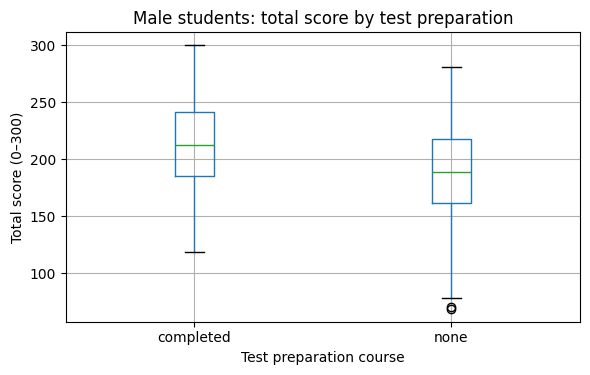

In [5]:
males = df.loc[df['gender'] == 'male'].copy()
display(males.groupby('test preparation course')[scores].agg(['count', 'mean', 'std']).round(2))
male_results = compare_scores(males, 'test preparation course', 'completed', 'none')
display(male_results)
report_primary(male_results)

# Inspect the score distributions in the two male groups.
males.boxplot(column='total score', by='test preparation course', figsize=(6, 4))
plt.title('Male students: total score by test preparation')
plt.suptitle('')
plt.xlabel('Test preparation course')
plt.ylabel('Total score (0–300)')
plt.tight_layout()
plt.show()

**Answer:** In the supplied dataset, 174 males completed preparation and 308 did not. Their mean total scores are **212.34** and **189.13**, respectively: a difference of **23.21 points**, t = **6.181**, p = **1.73 × 10⁻⁹**. We reject H0 at the 5% level. Completed-course males also have higher mean math, reading, and writing scores, with p < 0.001 in each subject. These are associations; the data do not establish that the course caused the differences.

## 3. Other differences of interest
Explore male versus female scores and standard versus free/reduced lunch scores. Each test compares two independent groups; no paired t-tests are appropriate.

In [6]:
gender_results = compare_scores(df, 'gender', 'male', 'female')
lunch_results = compare_scores(df, 'lunch', 'standard', 'free/reduced')
print('Gender comparison (A = male, B = female)')
display(gender_results)
report_primary(gender_results)
print('Lunch comparison (A = standard, B = free/reduced)')
display(lunch_results)
report_primary(lunch_results)

# Bonferroni adjustment across the 12 reported tests, as a sensitivity check.
all_results = pd.concat([male_results, gender_results, lunch_results], ignore_index=True)
all_results['Adjusted p (Bonferroni)'] = (all_results['p value'] * len(all_results)).clip(upper=1)
all_results['Significant after adjustment'] = all_results['Adjusted p (Bonferroni)'] < 0.05
display(all_results[['Group A', 'Group B', 'Score', 'p value',
                     'Adjusted p (Bonferroni)', 'Significant after adjustment']])

Gender comparison (A = male, B = female)


,Score,Group A,Group B,n A,n B,Mean A,Mean B,Difference (A - B),t statistic,p value,Decision
0,total score,male,female,482,518,197.512448,208.708494,-11.196046,-4.178886,3.186198e-05,Reject H0
1,math score,male,female,482,518,68.728216,63.633205,5.095011,5.398001,8.420838e-08,Reject H0
2,reading score,male,female,482,518,65.473029,72.608108,-7.135079,-7.968357,4.376297e-15,Reject H0
3,writing score,male,female,482,518,63.311203,72.467181,-9.155978,-9.997719,1.711809e-22,Reject H0


Total score: male mean = 197.51; female mean = 208.71.
Mean difference = -11.20; t = -4.179; p = 3.19e-05.
Reject H0: There is evidence of a difference in mean total scores.
Lunch comparison (A = standard, B = free/reduced)


,Score,Group A,Group B,n A,n B,Mean A,Mean B,Difference (A - B),t statistic,p value,Decision
0,total score,standard,free/reduced,645,355,212.511628,186.597183,25.914445,9.323207,1.582969e-19,Reject H0
1,math score,standard,free/reduced,645,355,70.034109,58.921127,11.112982,11.484100,5.539585e-28,Reject H0
2,reading score,standard,free/reduced,645,355,71.654264,64.653521,7.000742,7.292615,8.421689e-13,Reject H0
3,writing score,standard,free/reduced,645,355,70.823256,63.022535,7.800721,7.840866,1.716147e-14,Reject H0


Total score: standard mean = 212.51; free/reduced mean = 186.60.
Mean difference = 25.91; t = 9.323; p = 1.58e-19.
Reject H0: There is evidence of a difference in mean total scores.


,Group A,Group B,Score,p value,Adjusted p (Bonferroni),Significant after adjustment
0,completed,none,total score,1.726440e-09,2.071728e-08,True
1,completed,none,math score,3.265766e-05,3.918919e-04,True
2,completed,none,reading score,1.771540e-08,2.125848e-07,True
3,completed,none,writing score,6.232341e-15,7.478809e-14,True
4,male,female,total score,3.186198e-05,3.823437e-04,True
5,male,female,math score,8.420838e-08,1.010501e-06,True
6,male,female,reading score,4.376297e-15,5.251556e-14,True
7,male,female,writing score,1.711809e-22,2.054171e-21,True
8,standard,free/reduced,total score,1.582969e-19,1.899563e-18,True
9,standard,free/reduced,math score,5.539585e-28,6.647502e-27,True


**Additional findings:**
- Males have higher mean math scores (68.73 versus 63.63), while females have higher mean reading scores (72.61 versus 65.47) and writing scores (72.47 versus 63.31). Female mean total score is 208.71, compared with 197.51 for males (p = 3.19 × 10⁻⁵).
- Students with standard lunch have higher mean total scores (212.51) than those with free/reduced lunch (186.60), p = 1.58 × 10⁻¹⁹. This may reflect broader socioeconomic differences and does not demonstrate a causal effect of lunch type.
- All 12 reported comparisons remain statistically significant after the Bonferroni adjustment. The tests overlap because total score combines the subjects, so they should not be treated as independent pieces of evidence.